# 03 — Keras Fundamentals and Model Building

### From tensors and layers to a complete, reproducible training workflow

**Learning path:** `Deep Learning / Keras`  
**Notebook:** 03 of 12  
**Level:** Beginner → intermediate  
**Primary tools:** Python, NumPy, Matplotlib, Keras 3  
**Example domain:** Synthetic gene-expression-style data with three hypothetical subtypes (educational data only)

---

## Learning objectives

By the end of this notebook, you should be able to:

1. Describe tensors in Keras: rank, shape, dtype, and the batch axis.
2. Explain what a layer is, when its weights are created, and how to count its parameters.
3. Build models with the **Sequential** API and the **Functional** API, including a model with two inputs.
4. Write a small custom layer and recognize when subclassing is useful.
5. Use `compile()`, `fit()`, `evaluate()`, and `predict()` correctly and explain what each one does.
6. Choose a compatible combination of output activation, target encoding, and loss function.
7. Compare optimizers and metrics, and read learning curves.
8. Use callbacks (`EarlyStopping`, `ModelCheckpoint`, `ReduceLROnPlateau`, `CSVLogger`, and a custom callback).
9. Prepare data without leakage: stratified splitting and normalization fitted on the training set only.

> **Important:** The data in this notebook are synthetic and generated only to demonstrate the workflow. Nothing here is evidence about real biology. Real biological datasets begin in Notebook 04.

## 1. The Keras workflow at a glance

Almost every supervised Keras project follows the same cycle:

1. **Prepare data:** split, clean, and preprocess without leaking information from validation or test data.
2. **Define the model:** choose layers and connect them (Sequential, Functional, or subclassing).
3. **Compile:** choose an optimizer, a loss function, and metrics.
4. **Fit:** train the model on the training data while monitoring validation data.
5. **Evaluate and predict:** measure performance on held-out data and generate predictions.
6. **Save and reuse:** store the model together with enough information to reproduce its use.

This notebook walks through these steps in order. Notebook 01 gave you a first working example and Notebook 02 explained the mathematics; here we study the Keras API itself in a systematic way.

## 2. Set up the environment

As before, we use **Keras 3 with the TensorFlow backend**. The code in this notebook uses `keras.ops` and standard Keras APIs, so it is not tied to a TensorFlow-specific interface.

Uncomment the install line if needed. Select the backend **before** importing Keras.

In [ ]:
# If needed, install the packages in the active Jupyter environment:
# %pip install -U keras tensorflow numpy matplotlib

In [1]:
# Select the backend BEFORE importing Keras.
import os
os.environ["KERAS_BACKEND"] = "tensorflow"

import sys
import csv
import time
import numpy as np
import matplotlib.pyplot as plt
import keras

# Reproducibility: seeds Python, NumPy, and the backend random number generators.
keras.utils.set_random_seed(42)

# A folder for files produced by this notebook (logs, checkpoints, saved models).
ARTIFACT_DIR = "artifacts_03"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

print("Python:", sys.version.split()[0])
print("Keras:", keras.__version__)
print("Backend:", keras.backend.backend())
print("NumPy:", np.__version__)

Python: 3.11.0
Keras: 3.15.1
Backend: tensorflow
NumPy: 2.4.6


## 3. Tensors in Keras

Keras models consume and produce **tensors**: multidimensional arrays with a fixed **dtype** (such as `float32`) and a **shape**.

| Biological-style data | Typical shape | Meaning of the axes |
|---|---|---|
| Expression table | `(samples, genes)` | one row per sample |
| One-hot DNA sequences | `(samples, positions, 4)` | position along the sequence, one channel per nucleotide |
| Image batch | `(samples, height, width, channels)` | pixel grid with colour channels |

### 3.1 The batch axis

The first axis is almost always the **batch axis** (the number of samples). When you define a model, you usually specify the shape of **one sample** and leave the batch axis out:

```python
keras.layers.Input(shape=(20,))   # one sample has 20 features; the batch size stays flexible
```

### 3.2 Backend-independent operations: `keras.ops`

`keras.ops` provides tensor operations that work with whichever backend is active. NumPy arrays can be passed to Keras directly, and tensors can be converted back to NumPy when you need to inspect or plot values.

In [2]:
x_np = np.array([[1.0, 2.0, 3.0],
                 [4.0, 5.0, 6.0]], dtype="float32")

x = keras.ops.convert_to_tensor(x_np)
print("Tensor type :", type(x).__name__)
print("Shape       :", tuple(x.shape))
print("Dtype       :", keras.backend.standardize_dtype(x.dtype))

# Matrix product (2x3) @ (3x2) -> (2x2)
gram = keras.ops.matmul(x, keras.ops.transpose(x))
print("\nx @ x.T:\n", keras.ops.convert_to_numpy(gram))

# Reduction along an axis and broadcasting
col_means = keras.ops.mean(x, axis=0)
centered = x - col_means                       # (2,3) - (3,) broadcasts across rows
print("\nColumn means:", keras.ops.convert_to_numpy(col_means))
print("Centered:\n", keras.ops.convert_to_numpy(centered))

# Elementwise nonlinearity and dtype conversion
print("\nReLU(centered):\n", keras.ops.convert_to_numpy(keras.ops.relu(centered)))
print("Cast to int32:", keras.ops.convert_to_numpy(keras.ops.cast(x, "int32")).tolist())

Tensor type : EagerTensor
Shape       : (2, 3)
Dtype       : float32

x @ x.T:
 [[14. 32.]
 [32. 77.]]

Column means: [2.5 3.5 4.5]
Centered:
 [[-1.5 -1.5 -1.5]
 [ 1.5  1.5  1.5]]

ReLU(centered):
 [[0.  0.  0. ]
 [1.5 1.5 1.5]]
Cast to int32: [[1, 2, 3], [4, 5, 6]]


**Practical note:** A very common source of errors is a shape or dtype mismatch. When something fails, print the shapes first. For example, a classifier trained on `X` with shape `(N, 20)` expects every new input to have shape `(M, 20)`; a single sample must be passed as `(1, 20)`, not `(20,)`.

## 4. Layers: the building blocks

A **layer** is an object that holds state (weights) and defines a computation. A `Dense` layer with $U$ units and an input with $F$ features implements the affine transformation from Notebook 02:

$$
Z = XW + b, \qquad A = \phi(Z)
$$

where $W \in \mathbb{R}^{F \times U}$, $b \in \mathbb{R}^{U}$, and $\phi$ is the activation function.

### 4.1 Weights are created when the input shape is known

When you create a layer, Keras does not yet know $F$, so the weights do not exist. They are created ("the layer is *built*") the first time the layer sees an input shape. We can observe this directly.

In [3]:
rng_demo = np.random.default_rng(0)
X_demo = rng_demo.normal(size=(5, 3)).astype("float32")   # 5 samples, 3 features

dense = keras.layers.Dense(4, activation="relu", name="demo_dense")
print("Built before the first call?", dense.built)

out = dense(keras.ops.convert_to_tensor(X_demo))           # calling the layer builds it
print("Built after the first call? ", dense.built)
print("Output shape:", tuple(out.shape))

kernel, bias = dense.get_weights()
print("Kernel shape:", kernel.shape, "| Bias shape:", bias.shape)
print("Parameters  :", kernel.size + bias.size, "= (3 x 4) + 4")

Built before the first call? False
Built after the first call?  True
Output shape: (5, 4)
Kernel shape: (3, 4) | Bias shape: (4,)
Parameters  : 16 = (3 x 4) + 4


In [4]:
# Verify that a Dense layer computes exactly ReLU(XW + b), as derived in Notebook 02.
manual = np.maximum(0.0, X_demo @ kernel + bias)
print("Matches the manual computation:",
      np.allclose(manual, keras.ops.convert_to_numpy(out), atol=1e-6))

Matches the manual computation: True


### 4.2 Commonly used layers in this learning path

| Layer | Purpose | Notebook |
|---|---|---|
| `Dense` | Fully connected transformation | 01–07 |
| `Normalization` | Standardize features using statistics learned from training data | 03 |
| `Dropout`, `BatchNormalization` | Regularization and optimization aids | 06 |
| `Conv2D`, `MaxPooling2D` | Image feature extraction | 08–09 |
| `Conv1D` | Local patterns in sequences | 10 |
| `Concatenate` | Join several branches | 03 |

You rarely write a layer from scratch, but doing it once makes the Keras design much less mysterious (Section 9).

## 5. A synthetic dataset for this notebook

We generate a small three-class dataset that imitates the *structure* of a gene-expression experiment:

- **900 samples**, **20 expression-like features** (`gene_01` … `gene_20`);
- three hypothetical groups (`Subtype A`, `Subtype B`, `Subtype C`) with **unequal class sizes** (360 / 300 / 240);
- only **8 of the 20 features** carry class information; the rest are noise;
- features are deliberately placed on **different scales** so that normalization matters;
- two extra **covariates** (`age_years`, `tissue_purity`) that we will use in a two-input model.

Everything is generated with a fixed seed. The data are not real measurements.

In [5]:
rng = np.random.default_rng(42)

class_names = ["Subtype A", "Subtype B", "Subtype C"]
class_counts = [360, 300, 240]
n_features = 20
n_informative = 8

# Class-specific mean shifts, nonzero only for the informative features.
class_means = np.zeros((3, n_features))
class_means[:, :n_informative] = rng.normal(0.0, 0.9, size=(3, n_informative))

blocks, labels = [], []
for class_id, count in enumerate(class_counts):
    blocks.append(rng.normal(class_means[class_id], 1.2, size=(count, n_features)))
    labels.append(np.full(count, class_id))

X_expr = np.vstack(blocks)
y = np.concatenate(labels).astype("int32")

# Put features on very different scales/offsets (typical of raw measurements).
scales = rng.uniform(0.5, 5.0, size=n_features)
offsets = rng.uniform(2.0, 12.0, size=n_features)
X_expr = (X_expr * scales + offsets).astype("float32")

# Two additional covariates with a weak class association.
age_years = rng.normal(55, 10, size=len(y)) + np.array([-3, 0, 3])[y]
tissue_purity = np.clip(rng.normal(0.70, 0.12, size=len(y)), 0.30, 0.99)
X_cov = np.column_stack([age_years, tissue_purity]).astype("float32")

# Shuffle once, keeping rows aligned across X_expr, X_cov, and y.
order = rng.permutation(len(y))
X_expr, X_cov, y = X_expr[order], X_cov[order], y[order]

feature_names = [f"gene_{i:02d}" for i in range(1, n_features + 1)]
print("X_expr:", X_expr.shape, X_expr.dtype)
print("X_cov :", X_cov.shape, X_cov.dtype)
print("y     :", y.shape, y.dtype)
print("Class counts:", dict(zip(class_names, np.bincount(y).tolist())))
print("\nFeature ranges differ widely:")
print("  smallest feature mean:", round(float(X_expr.mean(axis=0).min()), 2))
print("  largest  feature mean:", round(float(X_expr.mean(axis=0).max()), 2))
print("  smallest feature std :", round(float(X_expr.std(axis=0).min()), 2))
print("  largest  feature std :", round(float(X_expr.std(axis=0).max()), 2))

X_expr: (900, 20) float32
X_cov : (900, 2) float32
y     : (900,) int32
Class counts: {'Subtype A': 360, 'Subtype B': 300, 'Subtype C': 240}

Feature ranges differ widely:
  smallest feature mean: 0.52
  largest  feature mean: 11.88
  smallest feature std : 0.63
  largest  feature std : 6.3


## 6. Data management and preprocessing

### 6.1 Stratified train / validation / test split

With unequal class sizes, a purely random split can distort class proportions, especially for small classes. A **stratified split** keeps approximately the same class proportions in every partition.

The function below splits each class separately and then combines the pieces. We use 70% training, 15% validation, and 15% test.

> **Rule:** the split happens **before** any preprocessing that learns from the data. Statistics computed on the full dataset leak information from the validation and test sets into training.

In [6]:
def stratified_split_indices(labels, fractions=(0.70, 0.15, 0.15), seed=42):
    """Return train/validation/test index arrays with preserved class proportions."""
    assert abs(sum(fractions) - 1.0) < 1e-9
    split_rng = np.random.default_rng(seed)
    train_idx, val_idx, test_idx = [], [], []
    for class_id in np.unique(labels):
        idx = split_rng.permutation(np.flatnonzero(labels == class_id))
        n_train = int(round(fractions[0] * len(idx)))
        n_val = int(round(fractions[1] * len(idx)))
        train_idx.append(idx[:n_train])
        val_idx.append(idx[n_train:n_train + n_val])
        test_idx.append(idx[n_train + n_val:])
    parts = [np.concatenate(p) for p in (train_idx, val_idx, test_idx)]
    return [split_rng.permutation(p) for p in parts]   # shuffle within each partition

train_idx, val_idx, test_idx = stratified_split_indices(y)

X_train_expr, X_val_expr, X_test_expr = X_expr[train_idx], X_expr[val_idx], X_expr[test_idx]
X_train_cov, X_val_cov, X_test_cov = X_cov[train_idx], X_cov[val_idx], X_cov[test_idx]
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]

# The partitions must be disjoint and cover every sample exactly once.
assert len(set(train_idx) | set(val_idx) | set(test_idx)) == len(y)
assert len(train_idx) + len(val_idx) + len(test_idx) == len(y)

for name, labels_part in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    proportions = np.bincount(labels_part) / len(labels_part)
    print(f"{name:>10}: n={len(labels_part):3d}  class proportions={np.round(proportions, 3)}")

     train: n=630  class proportions=[0.4   0.333 0.267]
validation: n=135  class proportions=[0.4   0.333 0.267]
      test: n=135  class proportions=[0.4   0.333 0.267]


### 6.2 Normalization: learn the statistics from the training set only

Neural networks usually train more reliably when input features are on comparable scales. A standard choice is **standardization**:

$$
x' = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}
$$

Keras provides this as a layer, `keras.layers.Normalization`. Its `adapt()` method estimates the mean and variance from the data you give it. Two design advantages:

- you call `adapt()` on **training data only**, which prevents leakage;
- the layer is part of the model, so the **same preprocessing is applied automatically** when the model is saved, reloaded, and used for prediction.

In [7]:
norm_expr = keras.layers.Normalization(axis=-1, name="normalize_expression")
norm_expr.adapt(X_train_expr)                 # statistics come from the TRAINING set only

train_scaled = keras.ops.convert_to_numpy(norm_expr(X_train_expr))
val_scaled = keras.ops.convert_to_numpy(norm_expr(X_val_expr))

print("Training features after normalization:")
print("  mean range:", np.round([train_scaled.mean(axis=0).min(), train_scaled.mean(axis=0).max()], 3))
print("  std  range:", np.round([train_scaled.std(axis=0).min(), train_scaled.std(axis=0).max()], 3))
print("Validation features (not exactly 0/1, which is expected):")
print("  mean range:", np.round([val_scaled.mean(axis=0).min(), val_scaled.mean(axis=0).max()], 3))
print("  std  range:", np.round([val_scaled.std(axis=0).min(), val_scaled.std(axis=0).max()], 3))

Training features after normalization:
  mean range: [-0.  0.]
  std  range: [1. 1.]
Validation features (not exactly 0/1, which is expected):
  mean range: [-0.171  0.211]
  std  range: [0.877 1.102]


Notice that the validation data are **not** perfectly centered. That is correct: they are transformed with training statistics, exactly as new, unseen samples would be in practice.

### 6.3 How data reach `fit()`

For small datasets, NumPy arrays are the simplest input to `fit()`. Keras handles shuffling and mini-batching internally. For large datasets or complex input pipelines, Keras also accepts dataset objects and generators; these are introduced with the TensorFlow path later.

A convenience argument, `validation_split=0.2`, takes the **last** 20% of the arrays *before* shuffling and ignores class proportions. For sorted or imbalanced data this can be misleading. In this curriculum we create validation sets explicitly, as above.

## 7. The Sequential API

`keras.Sequential` is the simplest way to build a model: a plain **stack of layers**, each with exactly one input and one output.

Use it when the data flow is a straight line. We build a multilayer perceptron (MLP) for three-class classification:

| Layer | Output shape | Role |
|---|---|---|
| Input | `(None, 20)` | one sample has 20 features |
| Normalization | `(None, 20)` | standardize using training statistics |
| Dense(32, ReLU) | `(None, 32)` | learn intermediate representations |
| Dense(16, ReLU) | `(None, 16)` | learn higher-level combinations |
| Dense(3, softmax) | `(None, 3)` | class probabilities |

`None` stands for the flexible batch size.

In [8]:
def build_mlp(hidden_units=(32, 16), name="mlp_classifier"):
    """Create a fresh, untrained Sequential classifier with its own adapted Normalization layer."""
    norm = keras.layers.Normalization(axis=-1, name="normalize_expression")
    norm.adapt(X_train_expr)                                   # training data only
    layers = [keras.layers.Input(shape=(n_features,), name="expression"), norm]
    for i, units in enumerate(hidden_units, start=1):
        layers.append(keras.layers.Dense(units, activation="relu", name=f"hidden_{i}"))
    layers.append(keras.layers.Dense(len(class_names), activation="softmax", name="class_probabilities"))
    return keras.Sequential(layers, name=name)

model = build_mlp()
model.summary()

Model: "mlp_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalize_expression            │ (None, 20)             │            41 │
│ (Normalization)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1 (Dense)                │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,292 (5.05 KB)

 Trainable params: 1,251 (4.89 KB)

 Non-trainable params: 41 (168.00 B)

In [9]:
# Verify the parameter formula P = (d x u) + u from Notebook 01 for every Dense layer.
expected = (20 * 32 + 32) + (32 * 16 + 16) + (16 * 3 + 3)
trainable = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
print("Expected trainable parameters:", expected)
print("Counted trainable parameters :", trainable)
assert trainable == expected

print("\nLayers:")
for layer in model.layers:
    print(f"  {layer.name:22} {type(layer).__name__:14} output={layer.output.shape}")

Expected trainable parameters: 1251
Counted trainable parameters : 1251

Layers:
  normalize_expression   Normalization  output=(None, 20)
  hidden_1               Dense          output=(None, 32)
  hidden_2               Dense          output=(None, 16)
  class_probabilities    Dense          output=(None, 3)


The `Normalization` layer contributes **non-trainable** values (the stored mean and variance), which is why the total parameter count in `model.summary()` is larger than the trainable count.

### 7.1 Building incrementally with `add()`

A Sequential model can also be assembled step by step. This is convenient when architecture depends on a loop or on a configuration.

In [10]:
incremental = keras.Sequential(name="incremental_demo")
incremental.add(keras.layers.Input(shape=(n_features,)))
incremental.add(keras.layers.Dense(8, activation="relu"))
incremental.add(keras.layers.Dense(3, activation="softmax"))
print("Number of layers:", len(incremental.layers))
print("Output shape for a batch of 4:", incremental(X_train_expr[:4]).shape)

Number of layers: 2
Output shape for a batch of 4: (4, 3)


## 8. The Functional API

The **Functional API** treats layers as functions applied to symbolic tensors. You describe a **graph** of layers: starting from one or more `Input` objects, passing through layers, and ending in one or more outputs.

Use it when a model has:

- multiple inputs or multiple outputs;
- branches that later merge (concatenation, addition);
- shared layers or skip connections (important for modern CNNs).

First, the same classifier as in Section 7, written in functional style.

In [11]:
norm_f = keras.layers.Normalization(axis=-1, name="normalize_expression")
norm_f.adapt(X_train_expr)

inputs = keras.layers.Input(shape=(n_features,), name="expression")
x = norm_f(inputs)
x = keras.layers.Dense(32, activation="relu", name="hidden_1")(x)
x = keras.layers.Dense(16, activation="relu", name="hidden_2")(x)
outputs = keras.layers.Dense(3, activation="softmax", name="class_probabilities")(x)

functional_model = keras.Model(inputs=inputs, outputs=outputs, name="functional_mlp")
functional_model.summary()

Model: "functional_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ expression (InputLayer)         │ (None, 20)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalize_expression            │ (None, 20)             │            41 │
│ (Normalization)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1 (Dense)                │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,292 (5.05 KB)

 Trainable params: 1,251 (4.89 KB)

 Non-trainable params: 41 (168.00 B)

### 8.1 A model with two inputs

Biological datasets often combine different kinds of information: high-dimensional molecular measurements and a few low-dimensional covariates. These may deserve different processing before being combined.

Our architecture has two branches that are joined with `Concatenate`:

```
expression (20) ──► Normalization ──► Dense(32) ──┐
                                                  ├─► Concatenate ──► Dense(16) ──► Dense(3, softmax)
covariates (2)  ──► Normalization ──► Dense(4)  ──┘
```

The input layers are **named**, so data can be supplied as a dictionary whose keys match those names.

In [12]:
norm_e = keras.layers.Normalization(axis=-1, name="normalize_expression")
norm_c = keras.layers.Normalization(axis=-1, name="normalize_covariates")
norm_e.adapt(X_train_expr)
norm_c.adapt(X_train_cov)

expr_in = keras.layers.Input(shape=(n_features,), name="expression")
cov_in = keras.layers.Input(shape=(2,), name="covariates")

e = keras.layers.Dense(32, activation="relu", name="expr_dense")(norm_e(expr_in))
c = keras.layers.Dense(4, activation="relu", name="cov_dense")(norm_c(cov_in))

merged = keras.layers.Concatenate(name="merge")([e, c])
h = keras.layers.Dense(16, activation="relu", name="joint_dense")(merged)
probs = keras.layers.Dense(3, activation="softmax", name="class_probabilities")(h)

multi_input_model = keras.Model(inputs=[expr_in, cov_in], outputs=probs, name="two_input_classifier")
multi_input_model.summary()

Model: "two_input_classifier"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ expression          │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ covariates          │ (None, 2)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalize_expressi… │ (None, 20)        │         41 │ expression[0][0]  │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalize_covariat… │ (None, 2)         │          5 │ covariates[0][0]  │
│ (Normalization)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expr_dense (Dense)  │ (None, 32)        │        672 │ normalize_expres… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cov_dense (Dense)   │ (None, 4)         │         12 │ normalize_covari… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ merge (Concatenate) │ (None, 36)        │          0 │ expr_dense[0][0], │
│                     │                   │            │ cov_dense[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ joint_dense (Dense) │ (None, 16)        │        592 │ merge[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_probabilities │ (None, 3)         │         51 │ joint_dense[0][0] │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,373 (5.37 KB)

 Trainable params: 1,327 (5.18 KB)

 Non-trainable params: 46 (192.00 B)

We will train this model briefly in Section 12 after introducing `compile()` and `fit()`. If you have Graphviz installed, `keras.utils.plot_model(model, show_shapes=True)` draws the graph; it is optional and not required for this curriculum.

### 8.2 Sequential or Functional?

| Situation | Recommended API |
|---|---|
| A straight stack of layers | Sequential |
| Several inputs or outputs | Functional |
| Branching, merging, skip connections | Functional |
| Custom behavior inside the forward pass | Custom layer or subclassed model |

Functional models are *data structures*: Keras knows every layer and every shape, so it can validate the architecture, print a summary, and save the model reliably.

## 9. Building from scratch: a custom layer

To see what Keras does inside `Dense`, we write our own version. A layer subclass typically defines:

- `__init__`: store configuration;
- `build(input_shape)`: create the weights once the input shape is known;
- `call(inputs)`: define the computation.

The weights are created with `add_weight()`, so Keras tracks them as trainable parameters.

In [13]:
class MyDense(keras.layers.Layer):
    """A minimal fully connected layer: activation(inputs @ kernel + bias)."""

    def __init__(self, units, activation=None, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.activation = keras.activations.get(activation)

    def build(self, input_shape):
        n_inputs = input_shape[-1]
        self.kernel = self.add_weight(
            shape=(n_inputs, self.units), initializer="glorot_uniform",
            trainable=True, name="kernel")
        self.bias = self.add_weight(
            shape=(self.units,), initializer="zeros",
            trainable=True, name="bias")

    def call(self, inputs):
        return self.activation(keras.ops.matmul(inputs, self.kernel) + self.bias)

my_layer = MyDense(4, activation="relu", name="my_dense")
my_out = my_layer(keras.ops.convert_to_tensor(X_demo))
print("Output shape:", tuple(my_out.shape))
print("Trainable parameters:", sum(int(np.prod(w.shape)) for w in my_layer.trainable_weights))

# It behaves like any other Keras layer and can be used inside a model.
custom_model = keras.Sequential([
    keras.layers.Input(shape=(3,)),
    MyDense(8, activation="relu", name="custom_hidden"),
    keras.layers.Dense(3, activation="softmax", name="class_probabilities"),
], name="model_with_custom_layer")
custom_model.summary()

Output shape: (5, 4)
Trainable parameters: 16



Model: "model_with_custom_layer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ custom_hidden (MyDense)         │ (None, 8)              │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 59 (236.00 B)

 Trainable params: 59 (236.00 B)

 Non-trainable params: 0 (0.00 B)

**When is a custom layer worth it?** When a computation is not available as a built-in layer, for example a biologically motivated transformation. For standard architectures, prefer the built-in layers: they are tested, optimized, and serialize without extra work. (A model containing a custom layer additionally needs the layer to be registered and to implement `get_config()` to be saved and reloaded; we do not need this here.)

A third option, subclassing `keras.Model` and writing a `call()` method, gives maximum flexibility but loses some of the automatic validation of the Functional API. We will use it only when necessary.

## 10. Compile: optimizer, loss, and metrics

`compile()` configures the learning process:

- **Optimizer:** how parameters are updated from gradients (Notebook 02).
- **Loss:** the quantity that is minimized.
- **Metrics:** additional quantities that are *reported* but not optimized.

### 10.1 Output, target encoding, and loss must match

| Task | Output layer | Target format | Loss |
|---|---|---|---|
| Binary classification | `Dense(1, "sigmoid")` | `0/1` vector | `binary_crossentropy` |
| Multiclass, integer labels | `Dense(K, "softmax")` | integers `0…K-1` | `sparse_categorical_crossentropy` |
| Multiclass, one-hot labels | `Dense(K, "softmax")` | one-hot rows | `categorical_crossentropy` |
| Regression | `Dense(1)` (linear) | real numbers | `mse`, `mae`, … |

Our labels are integers (`0`, `1`, `2`), so we use `sparse_categorical_crossentropy`. One-hot encoding is introduced in Notebook 04; the two choices give mathematically equivalent training and differ only in how the targets are stored.

A common alternative is to remove the softmax from the last layer (the outputs are then called **logits**) and use `SparseCategoricalCrossentropy(from_logits=True)`. This is often more numerically stable. We keep softmax in the model here so that `predict()` returns probabilities directly.

In [14]:
model = build_mlp()

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
)

print("Optimizer:", type(model.optimizer).__name__)
print("Loss     :", model.loss)

Optimizer: Adam
Loss     : sparse_categorical_crossentropy


## 11. Fit: training the model

`fit()` runs the training loop. The most important arguments are:

| Argument | Meaning |
|---|---|
| `x`, `y` | training inputs and targets |
| `epochs` | number of passes over the training data |
| `batch_size` | number of samples per parameter update (default 32) |
| `validation_data` | data used to monitor performance after each epoch; **never** used to update weights |
| `callbacks` | objects that react to training events (Section 14) |
| `shuffle` | reshuffle training data each epoch (default `True`) |
| `verbose` | 0 = silent, 1 = progress bar, 2 = one line per epoch |

With 630 training samples and `batch_size=32`, one epoch consists of $\lceil 630/32 \rceil = 20$ parameter updates.

In [15]:
history = model.fit(
    X_train_expr, y_train,
    validation_data=(X_val_expr, y_val),
    epochs=25,
    batch_size=32,
    verbose=2,
)

Epoch 1/25
20/20 - 1s - 68ms/step - accuracy: 0.3968 - loss: 1.0822 - val_accuracy: 0.5333 - val_loss: 1.0104
Epoch 2/25
20/20 - 0s - 6ms/step - accuracy: 0.5111 - loss: 1.0020 - val_accuracy: 0.6074 - val_loss: 0.9520
Epoch 3/25
20/20 - 0s - 6ms/step - accuracy: 0.5651 - loss: 0.9442 - val_accuracy: 0.6667 - val_loss: 0.9002
Epoch 4/25
20/20 - 0s - 7ms/step - accuracy: 0.6095 - loss: 0.8918 - val_accuracy: 0.6889 - val_loss: 0.8509
Epoch 5/25
20/20 - 0s - 6ms/step - accuracy: 0.6603 - loss: 0.8406 - val_accuracy: 0.7185 - val_loss: 0.8039
Epoch 6/25
20/20 - 0s - 6ms/step - accuracy: 0.6873 - loss: 0.7918 - val_accuracy: 0.7407 - val_loss: 0.7613
Epoch 7/25
20/20 - 0s - 6ms/step - accuracy: 0.7111 - loss: 0.7468 - val_accuracy: 0.7481 - val_loss: 0.7257
Epoch 8/25
20/20 - 0s - 6ms/step - accuracy: 0.7206 - loss: 0.7077 - val_accuracy: 0.7481 - val_loss: 0.6979
Epoch 9/25
20/20 - 0s - 6ms/step - accuracy: 0.7206 - loss: 0.6753 - val_accuracy: 0.7481 - val_loss: 0.6767
Epoch 10/25
20/20 

### 11.1 Reading the learning curves

`fit()` returns a `History` object. Its `history` attribute is a dictionary with one list per quantity: `loss`, `accuracy`, `val_loss`, and `val_accuracy`. Plotting these curves is the most basic diagnostic tool in deep learning.

Look for:

- both losses decreasing and then flattening → learning is working;
- training loss keeps falling while validation loss rises → overfitting begins (Notebook 06);
- both losses high and flat → underfitting, a poor learning rate, or uninformative inputs.

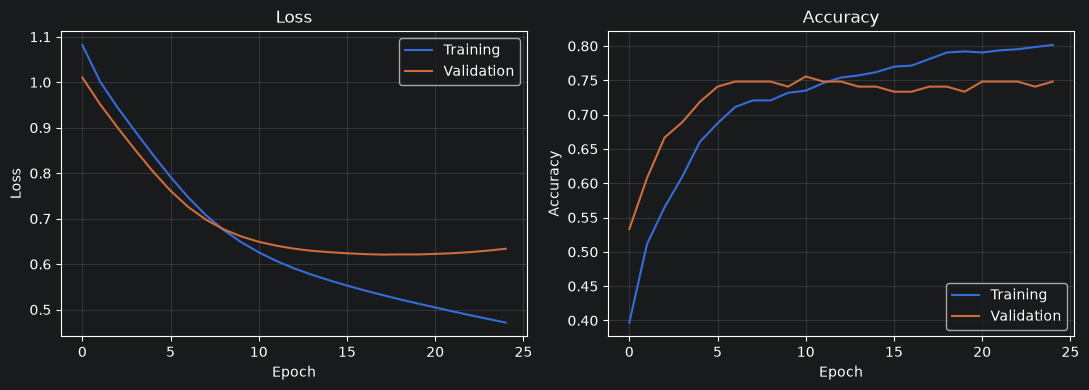

In [16]:
def plot_history(history, title_suffix=""):
    h = history.history
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(h["loss"], label="Training")
    axes[0].plot(h["val_loss"], label="Validation")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
    axes[0].set_title("Loss" + title_suffix)
    axes[0].legend(); axes[0].grid(alpha=0.25)

    axes[1].plot(h["accuracy"], label="Training")
    axes[1].plot(h["val_accuracy"], label="Validation")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
    axes[1].set_title("Accuracy" + title_suffix)
    axes[1].legend(); axes[1].grid(alpha=0.25)
    plt.tight_layout(); plt.show()

plot_history(history)

## 12. Evaluate and predict

- `evaluate(x, y)` returns the loss and metrics on the data you provide.
- `predict(x)` returns the model outputs for new inputs. For our softmax classifier, each row contains three probabilities that sum to 1.

The preprocessing is inside the model, so we pass **raw** (unscaled) features. We use the **validation** set here, because the test set is reserved for one final evaluation (Section 15).

In [17]:
val_results = model.evaluate(X_val_expr, y_val, verbose=0, return_dict=True)
print("Validation results:", {k: round(v, 4) for k, v in val_results.items()})

val_probs = model.predict(X_val_expr, verbose=0)
val_pred = np.argmax(val_probs, axis=1)

print("\nFirst 5 validation samples")
for i in range(5):
    print(f"  true={class_names[y_val[i]]:9} predicted={class_names[val_pred[i]]:9} "
          f"probabilities={np.round(val_probs[i], 3)}")

print("\nEach row of probabilities sums to 1:", np.allclose(val_probs.sum(axis=1), 1.0, atol=1e-5))

Validation results: {'accuracy': 0.7481, 'loss': 0.6338}

First 5 validation samples
  true=Subtype A predicted=Subtype A probabilities=[0.929 0.02  0.051]
  true=Subtype C predicted=Subtype B probabilities=[0.013 0.967 0.02 ]
  true=Subtype C predicted=Subtype C probabilities=[0.037 0.035 0.928]
  true=Subtype B predicted=Subtype B probabilities=[0.011 0.872 0.118]
  true=Subtype B predicted=Subtype B probabilities=[0.017 0.93  0.053]

Each row of probabilities sums to 1: True


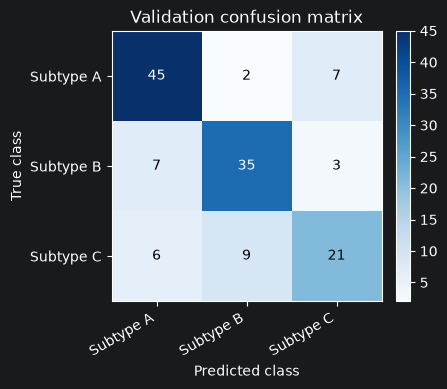

Recall for Subtype A: 0.833
Recall for Subtype B: 0.778
Recall for Subtype C: 0.583


In [18]:
def confusion_matrix_np(y_true, y_pred, n_classes):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)          # rows = true class, columns = predicted class
    return cm

def plot_confusion_matrix(cm, labels, title):
    fig, ax = plt.subplots(figsize=(4.5, 4))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=30, ha="right")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title(title)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout(); plt.show()

cm_val = confusion_matrix_np(y_val, val_pred, len(class_names))
plot_confusion_matrix(cm_val, class_names, "Validation confusion matrix")

per_class_recall = cm_val.diagonal() / cm_val.sum(axis=1)
for name, recall in zip(class_names, per_class_recall):
    print(f"Recall for {name}: {recall:.3f}")

Overall accuracy can hide differences between classes, particularly when classes are unequal in size. Always inspect per-class behavior. Notebook 04 develops multiclass evaluation, and Notebook 07 treats evaluation systematically.

### 12.1 Training the two-input model

Because the inputs are named, we pass dictionaries keyed by those names.

In [19]:
multi_input_model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
)

multi_history = multi_input_model.fit(
    {"expression": X_train_expr, "covariates": X_train_cov}, y_train,
    validation_data=({"expression": X_val_expr, "covariates": X_val_cov}, y_val),
    epochs=25, batch_size=32, verbose=0,
)

multi_val = multi_input_model.evaluate(
    {"expression": X_val_expr, "covariates": X_val_cov}, y_val, verbose=0, return_dict=True)
print("Two-input model, validation:", {k: round(v, 4) for k, v in multi_val.items()})
print("Expression-only model,  validation:", {k: round(v, 4) for k, v in val_results.items()})

Two-input model, validation: {'accuracy': 0.7407, 'loss': 0.6212}
Expression-only model,  validation: {'accuracy': 0.7481, 'loss': 0.6338}


Do not over-interpret a small difference between these two numbers: they come from one run each, on one validation split, with random initialization. The purpose of this section is the **mechanics** of multi-input models. Comparing models fairly requires repeated runs or cross-validation (Notebook 07).

## 13. Optimizers and metrics

### 13.1 Optimizers

An optimizer implements the update rule $\theta \leftarrow \theta - \eta \cdot (\text{some function of the gradient})$.

| Optimizer | Idea |
|---|---|
| `SGD` | Step against the gradient |
| `SGD(momentum=0.9)` | Accumulate a running direction to smooth and accelerate updates |
| `RMSprop` | Scale each parameter's step by a running average of squared gradients |
| `Adam` | Combines momentum-like and adaptive-scaling ideas; a strong default |

We compare them on the same architecture, data, and initial seed. This is a **demonstration**, not a benchmark: a single seed on a small dataset can easily reverse small differences, and each optimizer has its own sensitivity to the learning rate. Notebook 06 treats optimization in more depth.

SGD (lr=0.01)            final val_loss=0.7580  final val_accuracy=0.6593
SGD + momentum (0.9)     final val_loss=0.7377  final val_accuracy=0.6889
RMSprop (lr=0.001)       final val_loss=0.6141  final val_accuracy=0.7556
Adam (lr=0.001)          final val_loss=0.6259  final val_accuracy=0.7556


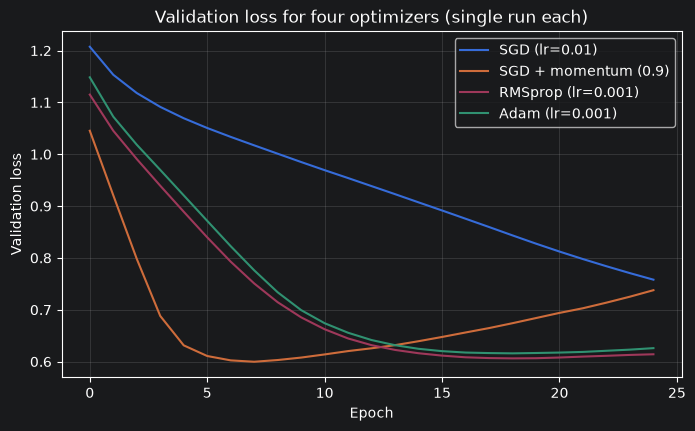

In [20]:
optimizer_factories = {
    "SGD (lr=0.01)":            lambda: keras.optimizers.SGD(learning_rate=0.01),
    "SGD + momentum (0.9)":     lambda: keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "RMSprop (lr=0.001)":       lambda: keras.optimizers.RMSprop(learning_rate=1e-3),
    "Adam (lr=0.001)":          lambda: keras.optimizers.Adam(learning_rate=1e-3),
}

optimizer_histories = {}
for label, factory in optimizer_factories.items():
    keras.utils.set_random_seed(42)                 # same initialization recipe for each run
    m = build_mlp(name="optimizer_demo")
    m.compile(optimizer=factory(), loss="sparse_categorical_crossentropy",
              metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")])
    h = m.fit(X_train_expr, y_train, validation_data=(X_val_expr, y_val),
              epochs=25, batch_size=32, verbose=0)
    optimizer_histories[label] = h.history
    print(f"{label:24} final val_loss={h.history['val_loss'][-1]:.4f}  "
          f"final val_accuracy={h.history['val_accuracy'][-1]:.4f}")

plt.figure(figsize=(8, 4.5))
for label, h in optimizer_histories.items():
    plt.plot(h["val_loss"], label=label)
plt.xlabel("Epoch"); plt.ylabel("Validation loss")
plt.title("Validation loss for four optimizers (single run each)")
plt.legend(); plt.grid(alpha=0.25); plt.show()

### 13.2 Metrics

A **metric** summarizes performance for humans. It is not necessarily the quantity being optimized. Keras metrics can be passed to `compile()` or used on their own:

In [21]:
# Standalone use: update_state() accumulates, result() reads the current value.
acc = keras.metrics.SparseCategoricalAccuracy(name="accuracy")
top2 = keras.metrics.SparseTopKCategoricalAccuracy(k=2, name="top2_accuracy")

acc.update_state(y_val, val_probs)
top2.update_state(y_val, val_probs)

print("Accuracy      :", round(float(keras.ops.convert_to_numpy(acc.result())), 4))
print("Top-2 accuracy:", round(float(keras.ops.convert_to_numpy(top2.result())), 4))

Accuracy      : 0.7481
Top-2 accuracy: 0.9037


Top-2 accuracy counts a prediction as correct if the true class is among the two most probable classes. It is always at least as high as ordinary accuracy and is sometimes informative when many classes are similar.

Choose metrics according to the scientific question, **before** looking at the final test result. Metrics for imbalanced problems (precision, recall, F1, ROC-AUC) are covered in Notebook 07.

## 14. Callbacks and model checkpoints

A **callback** is an object whose methods are called at specific moments of training (start of training, end of each epoch, and so on). Callbacks let you add behavior without rewriting the training loop.

| Callback | Purpose |
|---|---|
| `EarlyStopping` | Stop when a monitored quantity stops improving; optionally restore the best weights |
| `ModelCheckpoint` | Save the model (best or latest) during training |
| `ReduceLROnPlateau` | Lower the learning rate when progress stalls |
| `CSVLogger` | Write per-epoch metrics to a file |
| Custom `Callback` | Anything else you need |

**Why this matters:** with `EarlyStopping` you no longer have to guess the "right" number of epochs. You set a generous upper limit, and training stops when validation performance stops improving. The validation set is used for this decision, which is why the test set must remain untouched.

First, a tiny custom callback that records the time of each epoch:

In [22]:
class EpochTimer(keras.callbacks.Callback):
    """Record wall-clock seconds per epoch."""
    def on_train_begin(self, logs=None):
        self.epoch_seconds = []
    def on_epoch_begin(self, epoch, logs=None):
        self._start = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        self.epoch_seconds.append(time.perf_counter() - self._start)

checkpoint_path = os.path.join(ARTIFACT_DIR, "best_mlp.keras")
log_path = os.path.join(ARTIFACT_DIR, "training_log.csv")

timer = EpochTimer()
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(filepath=checkpoint_path, monitor="val_loss", save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5),
    keras.callbacks.CSVLogger(log_path),
    timer,
]

keras.utils.set_random_seed(42)
best_model = build_mlp(name="mlp_with_callbacks")
best_model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
)

cb_history = best_model.fit(
    X_train_expr, y_train,
    validation_data=(X_val_expr, y_val),
    epochs=200,                 # a generous upper bound; EarlyStopping decides when to stop
    batch_size=32,
    callbacks=callbacks,
    verbose=0,
)

n_epochs_run = len(cb_history.history["loss"])
best_epoch = int(np.argmin(cb_history.history["val_loss"])) + 1
print(f"Epochs actually run : {n_epochs_run} (limit was 200)")
print(f"Best epoch          : {best_epoch}  (val_loss={min(cb_history.history['val_loss']):.4f})")
print(f"Mean time per epoch : {np.mean(timer.epoch_seconds):.3f} s")
print("Checkpoint file     :", checkpoint_path, "| exists:", os.path.exists(checkpoint_path))

Epochs actually run : 27 (limit was 200)
Best epoch          : 19  (val_loss=0.6159)
Mean time per epoch : 0.168 s
Checkpoint file     : artifacts_03\best_mlp.keras | exists: True


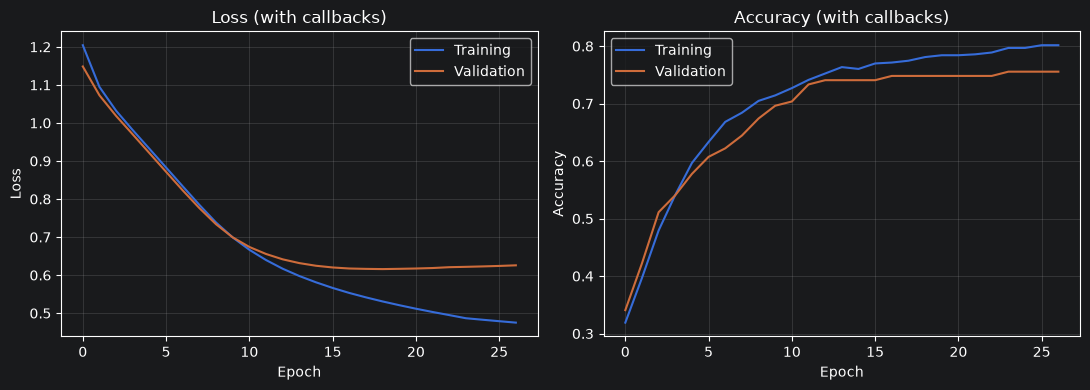

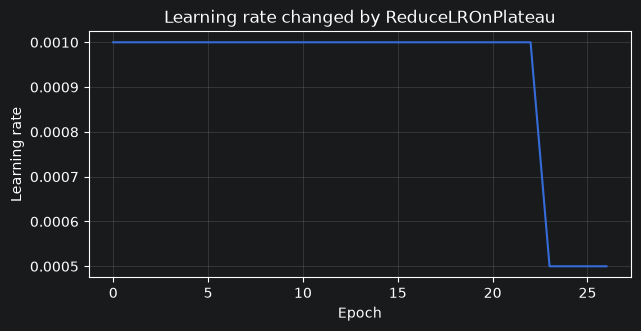

CSV log columns: ['epoch', 'accuracy', 'learning_rate', 'loss', 'val_accuracy', 'val_loss']
Logged epochs  : 55


In [23]:
plot_history(cb_history, " (with callbacks)")

lr_values = cb_history.history.get("learning_rate")
if lr_values is not None:
    plt.figure(figsize=(7, 3.2))
    plt.plot(lr_values)
    plt.xlabel("Epoch"); plt.ylabel("Learning rate")
    plt.title("Learning rate changed by ReduceLROnPlateau")
    plt.grid(alpha=0.25); plt.show()

# The CSV log is a plain file that can be opened in any spreadsheet or tool.
with open(log_path, newline="") as f:
    rows = list(csv.reader(f))
print("CSV log columns:", rows[0])
print("Logged epochs  :", len(rows) - 1)

### 14.1 Two different "best" models

- `EarlyStopping(restore_best_weights=True)` puts the best weights back into the **in-memory** model.
- `ModelCheckpoint(save_best_only=True)` saves the best model to **disk**, which survives a crashed kernel or a long training run.

Using both is common and harmless. Next, we reload the checkpoint from disk.

## 15. The final evaluation on the test set

Now that architecture, optimizer, and stopping rule have been decided using training and validation data, we evaluate **once** on the test set.

The model was reloaded from the file produced by `ModelCheckpoint`, and it accepts raw features because normalization is part of the model.

Test-set results
    accuracy: 0.6889
        loss: 0.6960


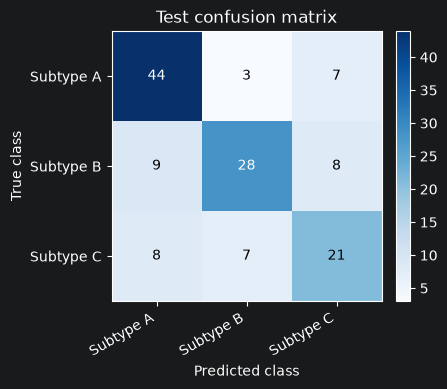

In [24]:
reloaded = keras.models.load_model(checkpoint_path)

test_results = reloaded.evaluate(X_test_expr, y_test, verbose=0, return_dict=True)
print("Test-set results")
for name, value in test_results.items():
    print(f"  {name:>10}: {value:.4f}")

test_pred = np.argmax(reloaded.predict(X_test_expr, verbose=0), axis=1)
cm_test = confusion_matrix_np(y_test, test_pred, len(class_names))
plot_confusion_matrix(cm_test, class_names, "Test confusion matrix")

### 15.1 Interpreting the result responsibly

The test accuracy estimates performance on **new samples from the same synthetic process**. It does not show that the model would work on a different laboratory, population, or technology. With only about 135 test samples, the estimate also has substantial uncertainty. These limitations apply even more strongly to real biological data, where batch effects, repeated samples from the same donor, and label noise are common.

### 15.2 Save and reload: model versus weights

| Method | File | Contains |
|---|---|---|
| `model.save("name.keras")` | `.keras` | architecture, weights, compile configuration, and optimizer state |
| `model.save_weights("name.weights.h5")` | `.weights.h5` | weights only; you must rebuild the architecture yourself |

Keep a record of the class-label mapping, feature order, data version, and package versions alongside the model file.

In [25]:
full_path = os.path.join(ARTIFACT_DIR, "final_mlp.keras")
weights_path = os.path.join(ARTIFACT_DIR, "final_mlp.weights.h5")

reloaded.save(full_path)
reloaded.save_weights(weights_path)

# Rebuild the same architecture, then load only the weights.
rebuilt = build_mlp(name="rebuilt_from_weights")
rebuilt.load_weights(weights_path)
# The Normalization statistics are stored as weights too, so they come back with load_weights().

original_out = reloaded.predict(X_test_expr[:10], verbose=0)
rebuilt_out = rebuilt.predict(X_test_expr[:10], verbose=0)
print("Predictions identical after reload:", np.allclose(original_out, rebuilt_out, atol=1e-5))

Predictions identical after reload: True


## 16. Common mistakes and how to diagnose them

| Symptom | Likely cause | What to check |
|---|---|---|
| `ValueError` about incompatible shapes | Input shape does not match the model | Print `X.shape` and `model.input_shape` |
| Loss is `nan` | Very large learning rate, unscaled inputs, or invalid targets | Lower the learning rate; inspect the inputs for `nan`/`inf` |
| Accuracy stuck at the majority-class rate | Model not learning, or imbalanced classes | Check the learning rate, normalization, and class proportions |
| Training accuracy ≫ validation accuracy | Overfitting | Fewer parameters, regularization, more data (Notebook 06) |
| Excellent validation score but poor real-world result | Data leakage or unrepresentative split | Was preprocessing fitted on training data only? Are related samples in separate partitions? |
| Loss-label error | Wrong target format for the chosen loss | Revisit the table in Section 10.1 |
| Backend does not change | `KERAS_BACKEND` set after `import keras` | Restart the kernel and run the setup cell first |
| Test result keeps "improving" | Test set used for decisions | Reserve a fresh test set or use cross-validation (Notebook 07) |

## 17. What did we learn?

You have now seen the full Keras workflow on a small, controlled example.

1. Keras operates on tensors with a shape and dtype; the first axis is the batch axis.
2. Layers hold weights, which are created when the input shape is known.
3. `Sequential` is for straight stacks of layers; the Functional API supports multiple inputs, branches, and merges.
4. A custom layer needs `build()` and `call()`; it clarifies what built-in layers do.
5. `compile()` selects the optimizer, loss, and metrics. Output activation, target encoding, and loss must be compatible.
6. `fit()` trains; `evaluate()` and `predict()` use the trained model. Validation data guide development; test data are used once at the end.
7. Callbacks automate stopping, checkpointing, learning-rate scheduling, and logging.
8. A `Normalization` layer adapted on training data keeps preprocessing consistent and avoids leakage.

### Key terms

| Term | Meaning |
|---|---|
| Tensor | A multidimensional array with a shape and dtype |
| Batch axis | The first axis, indexing samples |
| Layer | An object with weights and a computation |
| Built layer | A layer whose weights have been created |
| Sequential | A linear stack of layers |
| Functional API | A graph of layers with arbitrary inputs, outputs, and branches |
| Compile | Configure optimizer, loss, and metrics |
| Callback | An object hooked into the training loop |
| Checkpoint | A model saved during training |
| Logits | Raw outputs before softmax or sigmoid |

## 18. Exercises

Try to answer the conceptual questions before looking things up.

### Conceptual questions

1. What is the batch axis, and why is it left out of the `shape` argument of `Input`?
2. Why does a freshly created `Dense` layer have no weights yet?
3. A Dense layer maps 50 features to 12 units. How many trainable parameters does it have?
4. Give one situation where the Functional API is required and Sequential is not enough.
5. Why do the loss and the metric sometimes disagree about which model is better?
6. Why should `Normalization.adapt()` be called on training data only?
7. What is the difference between `ModelCheckpoint` and `EarlyStopping(restore_best_weights=True)`?
8. Why is `validation_split` risky for sorted or imbalanced data?

### Programming exercises

1. Change the hidden units in `build_mlp` to `(64, 32)` and `(8,)`. Compare parameter counts and validation curves.
2. Add a third hidden layer using the `add()` method on a Sequential model, and compare the result.
3. Replace the softmax output and `sparse_categorical_crossentropy` with logits and `SparseCategoricalCrossentropy(from_logits=True)`. Use `np.argmax` for predictions and explain what `predict()` now returns.
4. Convert the labels to one-hot vectors with `keras.utils.to_categorical` and switch to `categorical_crossentropy`. Verify that training behaves similarly.
5. Repeat the optimizer comparison with three different seeds. Do the rankings remain the same?
6. Write a callback that prints a message whenever the validation loss reaches a new best value.
7. Add `MyDense` as the output layer's predecessor in a full classifier and train it. Compare with the built-in `Dense` version.
8. Change `patience` in `EarlyStopping` to 2 and then 20. What happens to the stopping epoch and the final validation loss?

### Research-thinking exercise

Suppose the three subtypes are defined by a clinical expert from pathology reports and your samples include several tissue sections from the same patient. Explain how a random sample-level split could produce an optimistic test accuracy, and propose a split that avoids the problem.